In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
adata = sc.read_10x_h5("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/morris/GSM6675628_B4D12-RNA-r2-1_filtered_feature_bc_matrix.h5")

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
lineage_info_df = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/morris/b4.rna&atac.r1&2_master_rev1_annotated.csv')
lineage_info_df["barcode_stripped"] = [f[15:] for f in lineage_info_df["cell.bc"]] #for RNA delete first 16 characters
lineage_info_df = lineage_info_df.set_index("barcode_stripped")
# Keep only the first occurrence of each duplicate index
lineage_info_df = lineage_info_df.loc[~lineage_info_df.index.duplicated(keep='first')]
cells_with_lineage_info = lineage_info_df.index

In [5]:
cells_with_lineage_info_in_adata1 = [f for f in adata.obs_names if f in cells_with_lineage_info.values]
adata = adata[cells_with_lineage_info_in_adata1]
adata.obs["barcode"] = adata.obs_names.map(lineage_info_df["clone_id"])


/tmp/ipykernel_3205403/131653960.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["barcode"] = adata.obs_names.map(lineage_info_df["clone_id"])
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:

# Mark MT genes
adata.var["mt"] = adata.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)

# Filter cells with >3.5% MT
adata = adata[adata.obs["pct_counts_mt"] <= 3.5].copy()


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [7]:
adata

AnnData object with n_obs × n_vars = 851 × 31056
    obs: 'barcode', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

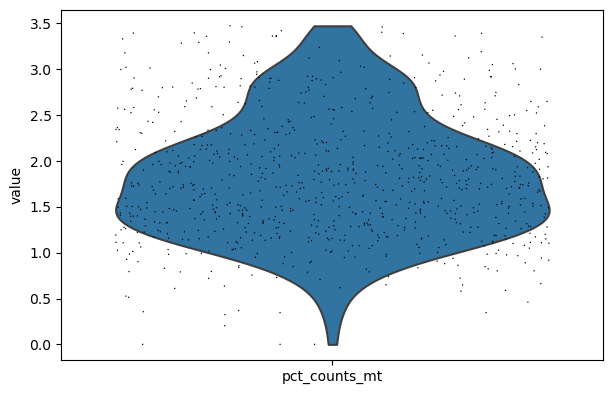

In [8]:
adata.var_names_make_unique()
sc.pl.violin(adata, 'pct_counts_mt', jitter=0.4)

In [9]:
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.normalize_total(adata , target_sum=1e4)
sc.pp.log1p(adata)
df = pd.DataFrame(adata.X.todense(), columns = adata.var_names)
df["barcode"] = adata.obs["barcode"].values
df["barcode_cont"] = pd.factorize(df["barcode"])[0]
df = df.drop(columns = ["barcode"])

In [11]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/morris_RNA.pkl
            
            )